In [1]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import sim_analysis_utilities as utilities
import smatch

Populating the interactive namespace from numpy and matplotlib


# S19A PSF not in S19AII bright star mask

We sample PSF using an old version of S19AII bright star mask

Here we check how many of the PSF is not in the new S19AII bright star mask

In [15]:
psfs1=astTable.Table.read('wrkDir/s19/s19-pre/info.csv')[0:2500]
psfs2=astTable.Table.read('wrkDir/s19/s19-pre/info2.csv')[0:2500]
cat=pyfits.getdata('wrkDir/database/smallcat-wl-s19-2-2.fits')[0::10]
fieldnames=np.unique(cat['fieldname'])

In [16]:
raP=psfs2['psf_ra']
decP=psfs2['psf_dec']
raG=cat['ra']
decG=cat['dec']

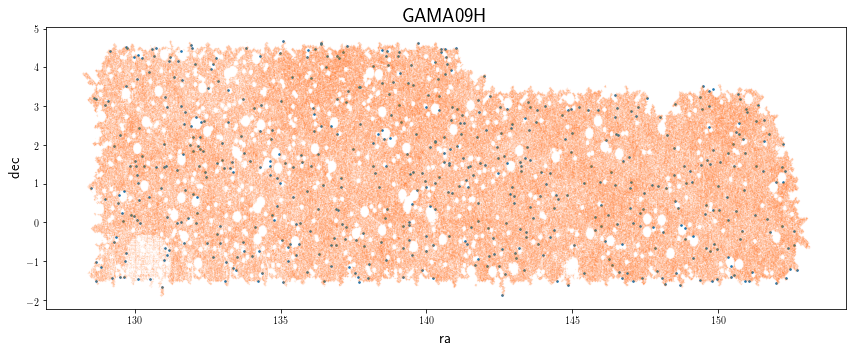

In [34]:
fn=fieldnames[0]
maskG=(cat['fieldname']==fn)
maskP=(psfs1['field']==fn)

fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raP[maskP],decP[maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [5]:
cat2=pyfits.getdata('wrkDir/database/s19-Hironao-2/fields/GAMA09H.fits')[0::10]

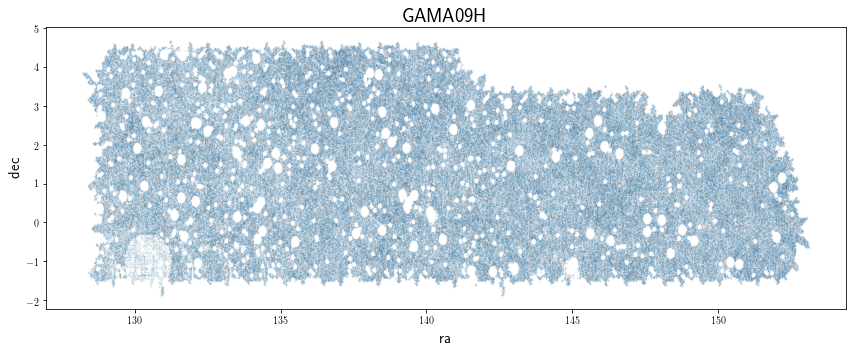

In [7]:
ra=cat2['i_ra']
dec=cat2['i_dec']
fn='GAMA09H'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

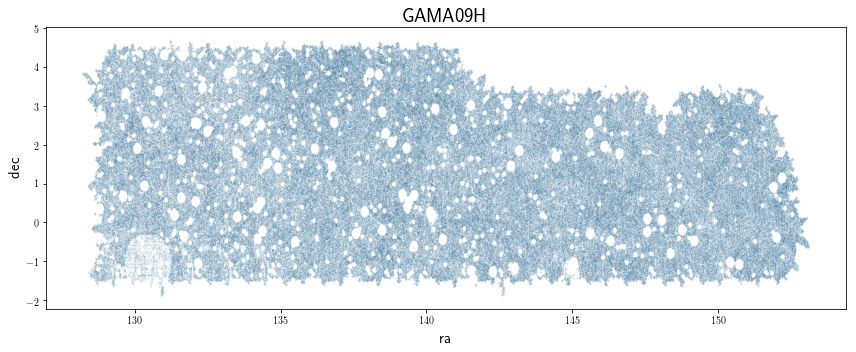

In [8]:
wlmask=utilities.update_wl_flags(cat2)['weak_lensing_flag']
ra=cat2[wlmask]['i_ra']
dec=cat2[wlmask]['i_dec']
fn='GAMA09H'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

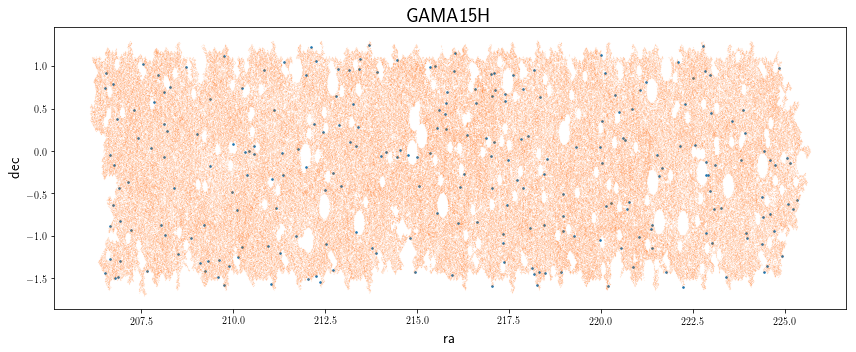

In [20]:
fn=fieldnames[1]
maskG=(cat['fieldname']==fn)
maskP=(psfs1['field']==fn)

fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raP[maskP],decP[maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.3)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

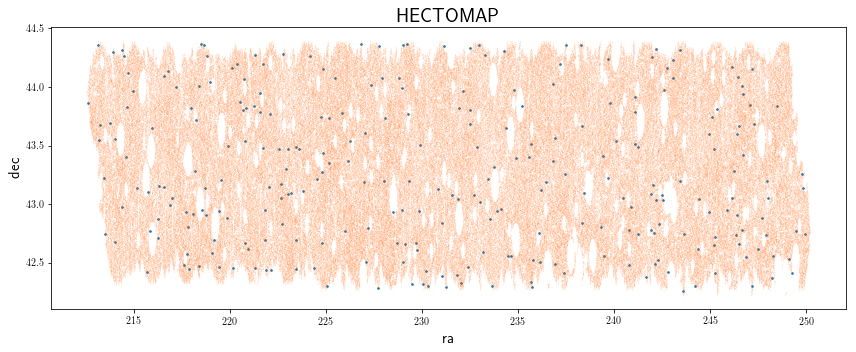

In [21]:
fn=fieldnames[2]
maskG=(cat['fieldname']==fn)
maskP=(psfs1['field']==fn)

fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raP[maskP],decP[maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.3)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

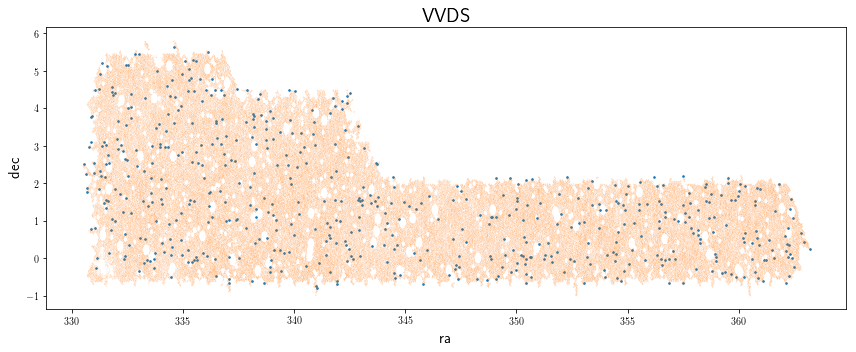

In [33]:
fn=fieldnames[3]
maskG=(cat['fieldname']==fn)
maskP=(psfs1['field']==fn)
raUP=raP[maskP]
decUP=decP[maskP]
raUG=raG[maskG]
decUG=decG[maskG]
addG=(raUG<300.).astype(int)*360
addP=(raUP<300.).astype(int)*360

fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raUP+addP,decUP,s=2.5)
plt.scatter(raUG+addG,decUG,s=0.01,alpha=0.1)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

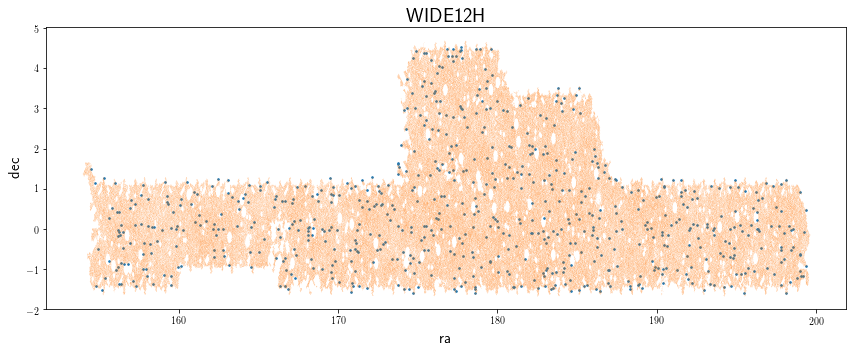

In [30]:
fn=fieldnames[4]
maskG=(cat['fieldname']==fn)
maskP=(psfs1['field']==fn)

fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raP[maskP],decP[maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.1)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

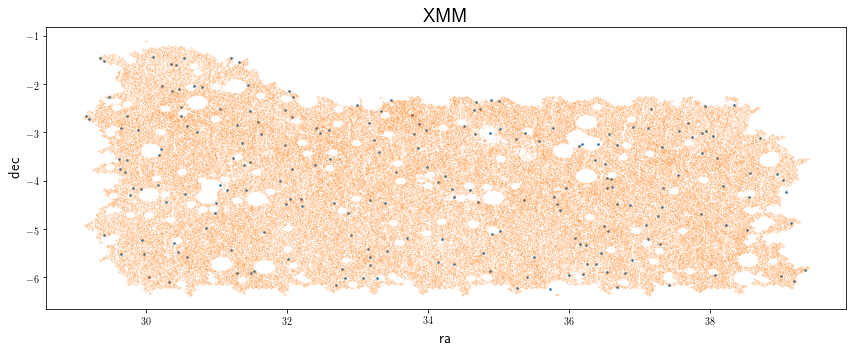

In [32]:
fn=fieldnames[5]
maskG=(cat['fieldname']==fn)
maskP=(psfs1['field']==fn)

fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raP[maskP],decP[maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.4)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [9]:
cat2=pyfits.getdata('wrkDir/database/s19-Hironao-2/fields/XMM.fits')[0::8]

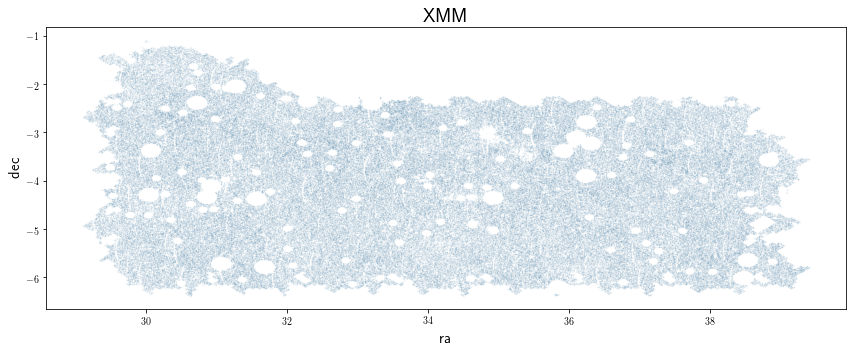

In [11]:
ra=cat2['i_ra']
dec=cat2['i_dec']
fn='XMM'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [ ]:
match   =   smatch.match(cat['ra'],cat['dec'],20./3600.,ra,dec,maxmatch=1)      # For a psf find the closest galaxy in HSC Wide field
mask=np.zeros(len(ra),dtype=bool)
mask[match['i2']]=True